In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Load the CSV file into a DataFrame
df = pd.read_csv('/Users/shaz/Desktop/DSSG Hackathon 2026 October/Data/carbon_footprint.csv')

# View the first 5 rows
print(df.head(10))



                                      page   client      rank  total_mb  \
0    https://cifi-tools.azurewebsites.net/  desktop   5000000    215.30   
1           https://courses20.zsmu.edu.ua/   mobile   5000000    136.38   
2                       https://heico.com/   mobile   5000000    130.81   
3         https://zanephillips.tumblr.com/   mobile  10000000    128.63   
4                https://jamomagazine.com/   mobile  50000000    128.40   
5                 https://www.armmash.com/   mobile  10000000    126.46   
6  https://winchesters-imagine.tumblr.com/   mobile  50000000    126.44   
7        https://ottomanladies.tumblr.com/   mobile  10000000    126.24   
8            https://lolbtsaus.tumblr.com/   mobile  50000000    125.95   
9                   https://tlnews.com.au/   mobile  10000000    124.14   

   co2_grams_per_view  img_weight_pct  video_weight_pct  
0             19.5145            0.00              0.00  
1             12.3615           99.11              0.00  


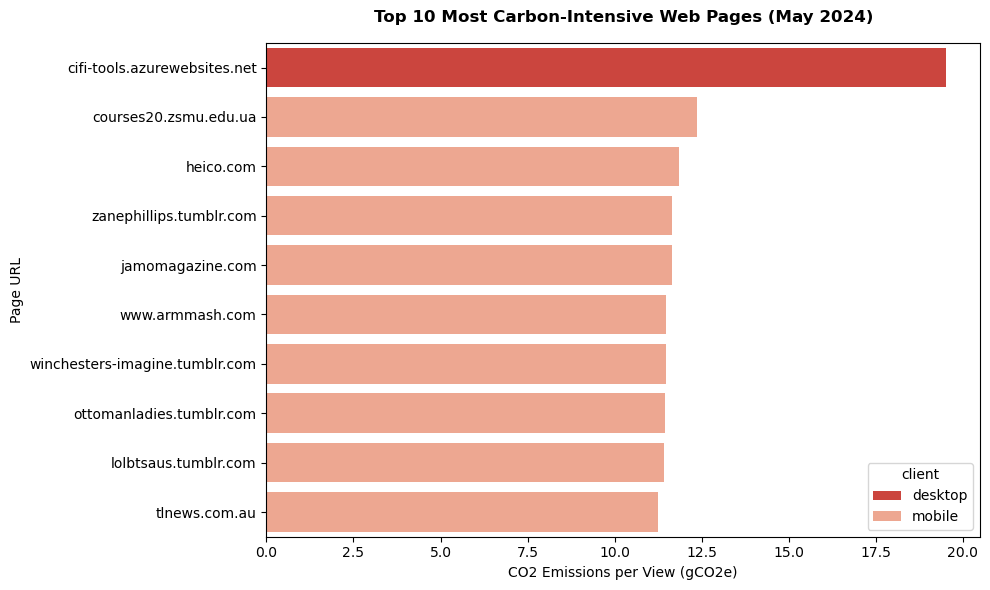

In [8]:
# Select top 10 rows and clean URLs for Y-axis display
top10 = df.head(10).copy()
top10['short_url'] = top10['page'].str.replace(r'https?://', '', regex=True).str.rstrip('/')

# Create figure
plt.figure(figsize=(10, 6))

# Plot horizontal bar chart
ax = sns.barplot(
    data=top10,
    x='co2_grams_per_view',
    y='short_url',
    hue='client',
    palette='Reds_r',
    dodge=False
)

# Set title and axis labels
plt.title('Top 10 Most Carbon-Intensive Web Pages (May 2024)', fontweight='bold', pad=15)
plt.xlabel('CO2 Emissions per View (gCO2e)')
plt.ylabel('Page URL')

# Adjust layout and display chart
plt.tight_layout()
plt.show()

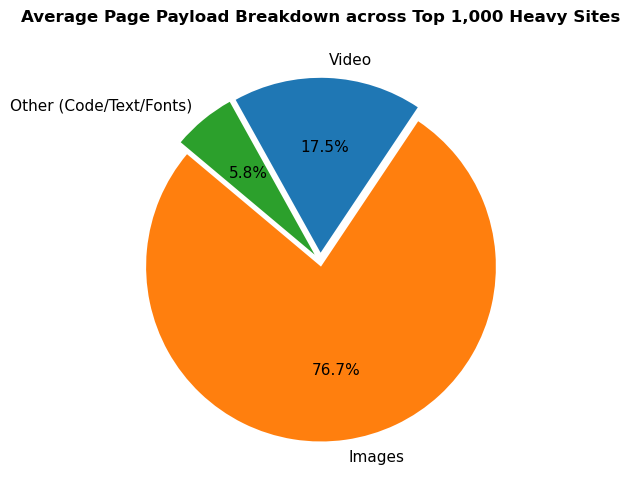

In [9]:

# Calculate the remaining weight percentage (Code, Text, Fonts)
df['other_weight_pct'] = np.maximum(0, 100 - df['img_weight_pct'] - df['video_weight_pct'])

# Compute overall average percentage breakdown
sizes = [
    df['img_weight_pct'].mean(),
    df['video_weight_pct'].mean(),
    df['other_weight_pct'].mean()
]

labels = ['Images', 'Video', 'Other (Code/Text/Fonts)']
colors = ['#ff7f0e', '#1f77b4', '#2ca02c']  # Orange, Blue, Green
explode = (0.03, 0.05, 0.05)               # Gaps between pie slices

# Create figure
plt.figure(figsize=(8, 5))

# Plot pie chart
plt.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    explode=explode,
    textprops={'fontsize': 11}
)

# Title
plt.title('Average Page Payload Breakdown across Top 1,000 Heavy Sites', fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

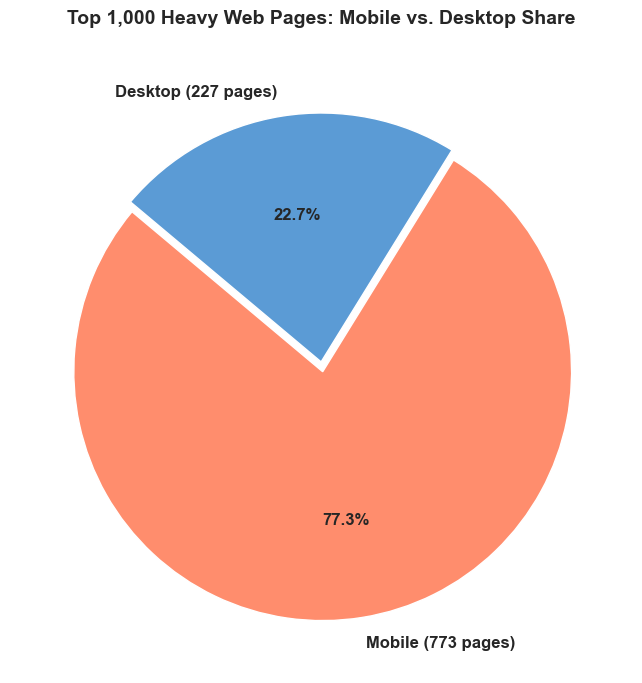

In [11]:
# Get value counts for mobile vs desktop
client_counts = df['client'].value_counts()

# Set styling
sns.set_theme(style='whitegrid')
plt.figure(figsize=(7, 7))

# Custom palette: Coral for Mobile, Blue for Desktop
colors = ['#ff8d6d', '#5b9bd5']
labels = [f"Mobile ({client_counts['mobile']} pages)", f"Desktop ({client_counts['desktop']} pages)"]

# Plot Pie Chart
plt.pie(
    [client_counts['mobile'], client_counts['desktop']],
    labels=labels,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    explode=(0.04, 0),
    textprops={'fontsize': 12, 'weight': 'bold'}
)

plt.title('Top 1,000 Heavy Web Pages: Mobile vs. Desktop Share', fontweight='bold', fontsize=14, pad=20)
plt.tight_layout()
plt.show()